# Q1 — Les liaisons les moins fiables du réseau

**Question** : quelles sont les liaisons TGV les moins fiables du réseau, et
cette instabilité s'aggrave-t-elle ou s'améliore-t-elle dans le temps ?

Le notebook suit `notebook_example.ipynb` : paramètres lus dans
`config/defaut.yaml` (section `liaisons_fiabilite`), données lues par
`lire_donnees` puis `nettoyer_regularite`. Voir `DATASHEET.md` pour la
documentation du jeu de données, les décisions de nettoyage et les limites.

**Plan** : 1. configuration · 2. données · 3. valeurs impossibles ·
4. classement et tendance · 5. classement à durée égale ·
6. sensibilité aux mois exceptionnels · 7. conclusion et limites.

## Définition de la métrique de fiabilité

Pour une liaison sur une période :

$$
\text{taux d'incidents} = \frac{\sum (\text{trains annulés} + \text{trains en retard} > 15\text{ min à l'arrivée})}{\sum \text{circulations prévues}}
$$

- Un train **annulé** ou **en retard de plus de 15 minutes à l'arrivée** est
  un incident de fiabilité. Le seuil fixe de 15 min (et non le seuil composite
  5 / 10 / 15 min de la SNCF) rend les liaisons comparables entre elles.
- Le taux est un **ratio de sommes** (pondéré par le trafic), jamais une
  moyenne de taux mensuels.
- Les lignes à 0 train prévu (73, mois où la liaison n'a pas circulé) sont
  retirées : elles n'ont pas de base de calcul.
- La tendance est la pente d'une régression linéaire du taux mensuel sur le
  temps, hors mois exceptionnels.

## 1. Charger la configuration

`charger_config()` lit `config/defaut.yaml`, vérifie toutes les valeurs, puis renvoie un objet `cfg`. Si une valeur est invalide, une erreur `ConfigInvalide` indique la clé en cause.

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from railinsight.config import charger_config

cfg = charger_config()
p = cfg.liaisons_fiabilite

COVID_DEBUT = pd.Period(p.covid_debut, freq="M")  # exclu de la pente uniquement
COVID_FIN = pd.Period(p.covid_fin, freq="M")
TOP_N = p.top_n

GRAINE = cfg.graine  # graine commune à tout le projet

# Grèves et confinements documentés puis confirmés par les données (DATASHEET §12.1)
MOIS_EXCEPTIONNELS = {
    "2018-04", "2018-05", "2018-06", "2019-12", "2020-01",
    "2020-03", "2020-04", "2020-05", "2020-06", "2020-11", "2020-12",
    "2021-04", "2021-05", "2022-12", "2023-01", "2023-02", "2023-03",
    "2024-02", "2026-06",
}  # fmt: skip

print("fenêtre COVID :", COVID_DEBUT, "->", COVID_FIN)
print("top_n :", TOP_N)
print("mois exceptionnels documentés :", len(MOIS_EXCEPTIONNELS))

fenêtre COVID : 2020-03 -> 2021-06
top_n : 10
mois exceptionnels documentés : 19


## 2. Charger et nettoyer les données

`lire_donnees` contrôle le schéma et renomme les colonnes (`prevus`, `annules`, `retards_sup_15min`…). `nettoyer_regularite` applique les règles communes du projet sans supprimer de ligne. On retire ensuite les lignes sans train prévu avec `retirer_sans_train`.

In [7]:
from railinsight.analysis.donnees import lire_donnees
from railinsight.analysis.nettoyage import nettoyer_regularite, retirer_sans_train

brut = nettoyer_regularite(lire_donnees(cfg.chemins.donnees))
data = retirer_sans_train(brut)

print("lignes lues :", len(brut), "| après retrait des mois sans train :", len(data))
data.head()

42 ligne(s) en double sur (mois, gare_depart, gare_arrivee), conservées


lignes lues : 12907 | après retrait des mois sans train : 12834


,date,service,gare_depart,gare_arrivee,duree_moyenne,prevus,annules,retards_depart,retard_moyen_retardes_depart,retard_moyen_depart,...,prct_cause_materiel,prct_cause_gare,prct_cause_voyageurs,mois,gare_a,gare_b,liaison,circules,minutes_retard,circules_mesures
0,2018-01-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141.0,870.0,5.0,289.0,11.247809,3.693179,...,15.966387,5.042017,0.840336,2018-01,BORDEAUX ST JEAN,PARIS MONTPARNASSE,BORDEAUX ST JEAN - PARIS MONTPARNASSE,865.0,5632.116667,865.0
1,2018-01-01,National,LE MANS,PARIS MONTPARNASSE,56.0,406.0,1.0,213.0,8.479969,4.567119,...,16.666667,8.333333,3.333333,2018-01,LE MANS,PARIS MONTPARNASSE,LE MANS - PARIS MONTPARNASSE,405.0,2172.233333,405.0
2,2018-01-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166.0,226.0,0.0,21.0,6.239683,0.286283,...,16.666667,5.555556,11.111111,2018-01,LA ROCHELLE VILLE,PARIS MONTPARNASSE,LA ROCHELLE VILLE - PARIS MONTPARNASSE,226.0,664.000000,226.0
3,2018-01-01,National,PARIS MONTPARNASSE,NANTES,124.0,508.0,3.0,71.0,7.235211,0.734290,...,20.370370,5.555556,1.851852,2018-01,NANTES,PARIS MONTPARNASSE,NANTES - PARIS MONTPARNASSE,505.0,2672.566667,505.0
4,2018-01-01,National,POITIERS,PARIS MONTPARNASSE,94.0,472.0,4.0,224.0,6.784673,3.229701,...,15.789474,1.754386,1.754386,2018-01,PARIS MONTPARNASSE,POITIERS,PARIS MONTPARNASSE - POITIERS,468.0,2284.950000,468.0


In [8]:
colonnes_q1 = ["prevus", "annules", "retards_sup_15min", "duree_moyenne"]

print("--- Statistiques descriptives ---")
print(data[colonnes_q1].describe())
print("\n--- Valeurs manquantes ---")
print(data[colonnes_q1].isna().sum())
print("\n--- Doublons sur (mois, gare_depart, gare_arrivee) ---")
# été 2025 : une ligne National + une International, flux distincts additionnés plus bas
print(data.duplicated(["mois", "gare_depart", "gare_arrivee"]).sum())

--- Statistiques descriptives ---
             prevus       annules  retards_sup_15min  duree_moyenne
count  12834.000000  12834.000000       12834.000000   12834.000000
mean     274.998987      8.282920          28.261259     171.664017
std      183.478803     21.862605          23.884957      87.023410
min        1.000000      0.000000           0.000000      35.000000
25%      153.000000      0.000000          11.000000     100.000000
50%      232.000000      2.000000          22.000000     164.000000
75%      367.000000      6.750000          38.000000     224.000000
max     1104.000000    297.000000         312.000000     786.000000

--- Valeurs manquantes ---
prevus               0
annules              0
retards_sup_15min    0
duree_moyenne        0
dtype: int64

--- Doublons sur (mois, gare_depart, gare_arrivee) ---
42


## 3. Valeurs impossibles

Règle D4c de la datasheet : un mois où il y a **plus de trains en retard > 15 min que de trains circulés** est impossible. On invalide le champ (`NaN`), pas la ligne. Comme le nombre d'incidents du mois devient inconnu, ce mois est écarté du numérateur **et** du dénominateur du taux (ratio sur paires valides).

Les 63 autres cas signalés par la datasheet sont des mois à 0 train prévu, déjà retirés.

In [9]:
impossible = data["retards_sup_15min"] > data["circules"]
print("mois avec plus de retards > 15 min que de trains circulés :", impossible.sum())
print(
    data.loc[
        impossible,
        ["mois", "gare_depart", "gare_arrivee", "circules", "retards_sup_15min"],
    ]
)

data["retards_sup_15min"] = data["retards_sup_15min"].mask(impossible)

mois avec plus de retards > 15 min que de trains circulés : 2
         mois gare_depart gare_arrivee  circules  retards_sup_15min
3415  2020-04  PARIS LYON       ZURICH      17.0               20.0
3453  2020-04  STRASBOURG    PARIS EST       3.0                4.0


## 4. Classement et tendance

Une liaison est orientée (A → B). Les lignes d'un même mois et d'une même liaison (doublons National / International de l'été 2025) sont additionnées.

In [10]:
work = pd.DataFrame(
    {
        "route": data["gare_depart"] + " → " + data["gare_arrivee"],
        "month": data["date"].dt.to_period("M"),
        "planned": data["prevus"],
        "incidents": data["annules"] + data["retards_sup_15min"],
        "duree": data["duree_moyenne"],
    }
)
work = work[work["incidents"].notna()]  # paires valides uniquement
work.head()

,route,month,planned,incidents,duree
0,BORDEAUX ST JEAN → PARIS MONTPARNASSE,2018-01,870.0,115.0,141.0
1,LE MANS → PARIS MONTPARNASSE,2018-01,406.0,33.0,56.0
2,PARIS MONTPARNASSE → LA ROCHELLE VILLE,2018-01,226.0,11.0,166.0
3,PARIS MONTPARNASSE → NANTES,2018-01,508.0,42.0,124.0
4,POITIERS → PARIS MONTPARNASSE,2018-01,472.0,46.0,94.0


In [11]:
# Classement global : liaisons les moins fiables sur toute la période
ranking = (
    work.groupby("route")
    .agg(planned=("planned", "sum"), incidents=("incidents", "sum"))
    .assign(rate=lambda d: d["incidents"] / d["planned"])
    .sort_values("rate", ascending=False)
)
worst_routes = ranking.head(TOP_N)
print("liaisons classées :", len(ranking))
worst_routes

liaisons classées : 130


,planned,incidents,rate
route,,,
ITALIE → PARIS LYON,7208.0,2592.0,0.359600
MADRID → MARSEILLE ST CHARLES,929.0,242.0,0.260495
PARIS EST → STUTTGART,12798.0,3317.0,0.259181
LYON PART DIEU → LILLE,30165.0,7661.0,0.253970
CHAMBERY CHALLES LES EAUX → PARIS LYON,22528.0,5625.0,0.249689
MARSEILLE ST CHARLES → LILLE,20074.0,4959.0,0.247036
PARIS EST → FRANCFORT,15855.0,3695.0,0.233050
MACON LOCHE → PARIS LYON,23058.0,5253.0,0.227817
ANNECY → PARIS LYON,14678.0,3322.0,0.226325


In [12]:
monthly = work.groupby(["route", "month"], as_index=False).agg(
    planned=("planned", "sum"), incidents=("incidents", "sum")
)
monthly["rate"] = monthly["incidents"] / monthly["planned"]
monthly["t"] = (monthly["month"] - monthly["month"].min()).apply(lambda m: m.n)


def pentes(mois_exclus: set[str]) -> pd.Series:
    """Pente du taux mensuel par liaison, en points de % par an, hors `mois_exclus`."""
    garde = monthly[~monthly["month"].astype(str).isin(mois_exclus)]

    def pente(g: pd.DataFrame) -> float:
        if g["t"].nunique() < 2:
            return np.nan
        return np.polyfit(g["t"], g["rate"], 1)[0] * 12 * 100

    return garde.groupby("route").apply(pente, include_groups=False)


FENETRE_COVID = {str(m) for m in pd.period_range(COVID_DEBUT, COVID_FIN, freq="M")}
pente_covid = pentes(FENETRE_COVID)

evolution = worst_routes.assign(pente_pt_an=pente_covid)
evolution["tendance"] = np.where(
    evolution["pente_pt_an"] > 0, "se dégrade", "s'améliore"
)
evolution.round(4)

,planned,incidents,rate,pente_pt_an,tendance
route,,,,,
ITALIE → PARIS LYON,7208.0,2592.0,0.3596,-0.6180,s'améliore
MADRID → MARSEILLE ST CHARLES,929.0,242.0,0.2605,-1.8793,s'améliore
PARIS EST → STUTTGART,12798.0,3317.0,0.2592,5.1492,se dégrade
LYON PART DIEU → LILLE,30165.0,7661.0,0.2540,-1.0258,s'améliore
CHAMBERY CHALLES LES EAUX → PARIS LYON,22528.0,5625.0,0.2497,-0.9186,s'améliore
MARSEILLE ST CHARLES → LILLE,20074.0,4959.0,0.2470,-0.8952,s'améliore
PARIS EST → FRANCFORT,15855.0,3695.0,0.2330,2.0512,se dégrade
MACON LOCHE → PARIS LYON,23058.0,5253.0,0.2278,0.2966,se dégrade
ANNECY → PARIS LYON,14678.0,3322.0,0.2263,-0.9973,s'améliore


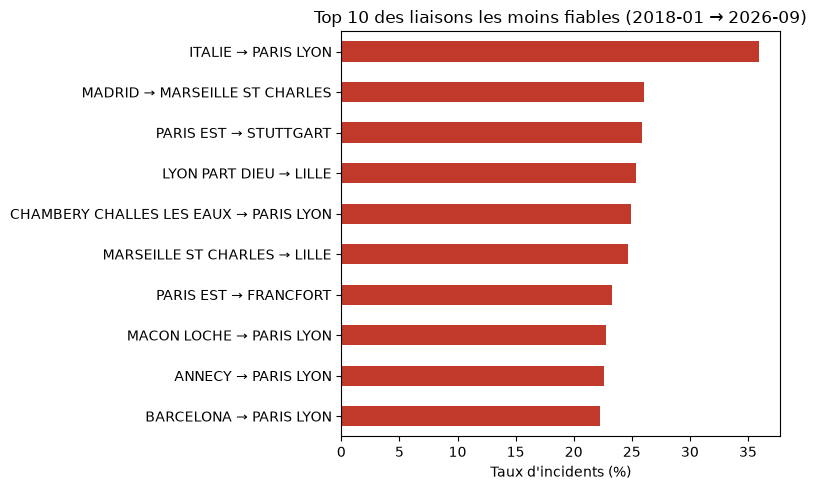

In [13]:
# Visualisation : classement des liaisons les moins fiables
periode = f"{data['mois'].min()} → {data['mois'].max()}"
fig, ax = plt.subplots(figsize=(8, 5))
worst_routes["rate"].sort_values().mul(100).plot.barh(ax=ax, color="#c0392b")
ax.set_xlabel("Taux d'incidents (%)")
ax.set_ylabel("")
ax.set_title(f"Top {TOP_N} des liaisons les moins fiables ({periode})")
plt.tight_layout()
plt.show()

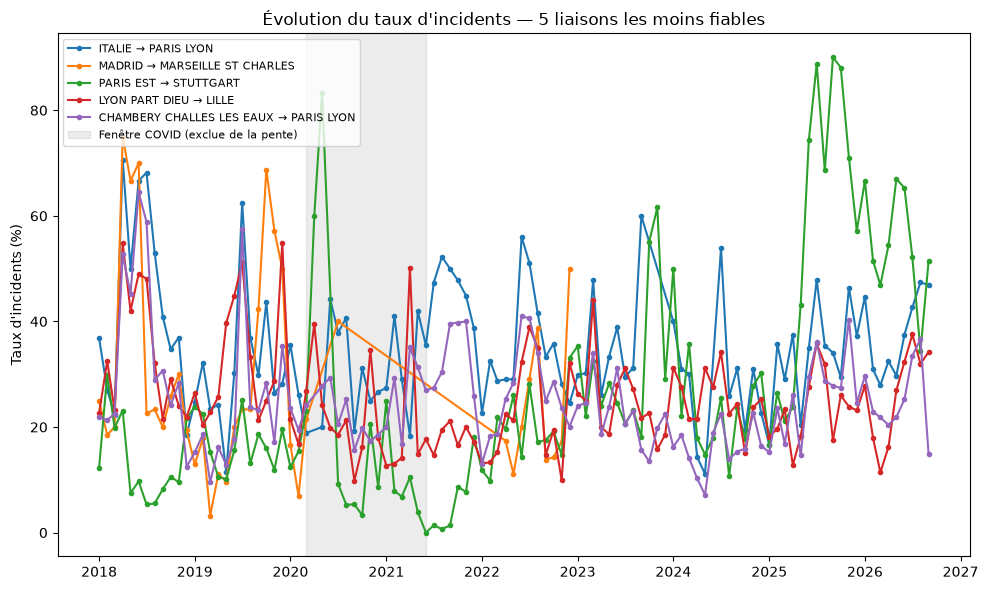

In [14]:
# Visualisation : évolution mensuelle du taux d'incidents pour les pires liaisons
fig, ax = plt.subplots(figsize=(10, 6))
for route in worst_routes.index[:5]:
    serie = monthly[monthly["route"] == route].sort_values("month")
    ax.plot(
        serie["month"].dt.to_timestamp(),
        serie["rate"] * 100,
        marker="o",
        markersize=3,
        label=route,
    )
ax.axvspan(
    COVID_DEBUT.to_timestamp(),
    COVID_FIN.to_timestamp(),
    color="grey",
    alpha=0.15,
    label="Fenêtre COVID (exclue de la pente)",
)
ax.set_ylabel("Taux d'incidents (%)")
ax.set_title("Évolution du taux d'incidents — 5 liaisons les moins fiables")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 5. Classement à durée égale

Un long trajet laisse plus de temps pour accumuler 15 min de retard : le classement brut pénalise mécaniquement les longues liaisons (souvent internationales). Comme en Q3, on retire l'effet de la durée $D$ (médiane de la durée moyenne du trajet) :

$$\tilde{\tau}_r = \tau_r - \hat{b}\,(\ln D_r - \overline{\ln D})$$

où $\hat{b}$ est la pente de la régression du taux sur $\ln D$, à travers toutes les liaisons. Lecture : « taux attendu si la liaison avait la durée moyenne du réseau ».

In [15]:
ranking["duree"] = work[work["duree"] > 0].groupby("route")["duree"].median()
log_duree = np.log(ranking["duree"])

rho = spearmanr(log_duree, ranking["rate"], nan_policy="omit").statistic
b = np.polyfit(log_duree, ranking["rate"], 1)[0]
ranking["rate_ajuste"] = ranking["rate"] - b * (log_duree - log_duree.mean())

print(f"corrélation de Spearman taux / durée : {rho:.2f}")
print(f"pente b : {b:.4f} (taux par unité de ln(durée))")

top_ajuste = ranking.sort_values("rate_ajuste", ascending=False).head(TOP_N)
communes = top_ajuste.index.intersection(worst_routes.index)
print(f"liaisons communes aux deux top {TOP_N} : {len(communes)}")
top_ajuste[["duree", "rate", "rate_ajuste"]].round(3)

corrélation de Spearman taux / durée : 0.71
pente b : 0.0633 (taux par unité de ln(durée))
liaisons communes aux deux top 10 : 7


,duree,rate,rate_ajuste
route,,,
ITALIE → PARIS LYON,434.5,0.360,0.294
MACON LOCHE → PARIS LYON,98.0,0.228,0.256
PARIS EST → STUTTGART,190.0,0.259,0.246
LYON PART DIEU → LILLE,188.0,0.254,0.241
CHAMBERY CHALLES LES EAUX → PARIS LYON,178.0,0.250,0.240
LYON PART DIEU → MARNE LA VALLEE,108.0,0.215,0.238
LYON PART DIEU → MARSEILLE ST CHARLES,105.0,0.208,0.232
LYON PART DIEU → MONTPELLIER,114.0,0.190,0.209
PARIS EST → FRANCFORT,228.0,0.233,0.208


## 6. Sensibilité aux mois exceptionnels

La tendance de la section 4 exclut la fenêtre COVID (2020-03 → 2021-06). La Q3 exclut à la place les 19 mois de grèves et de confinements documentés et confirmés par les données (DATASHEET §12). On compare trois règles : fenêtre COVID, mois documentés, aucune exclusion.

In [16]:
regles = {
    "fenêtre COVID": FENETRE_COVID,
    "mois documentés": MOIS_EXCEPTIONNELS,
    "aucune exclusion": set(),
}
toutes_pentes = pd.DataFrame({nom: pentes(mois) for nom, mois in regles.items()})

print("Pentes du top 10 (points de % par an) :")
print(toutes_pentes.loc[worst_routes.index].round(2).to_string())

meme_signe = np.sign(toutes_pentes["fenêtre COVID"]) == np.sign(
    toutes_pentes["mois documentés"]
)
print(
    f"\nmême sens de tendance (COVID / documentés), top 10 : "
    f"{meme_signe[worst_routes.index].sum()} / {TOP_N}"
)
print(f"même sens de tendance, toutes liaisons : {meme_signe.mean():.0%}")
print("\nliaisons qui se dégradent (sur", len(toutes_pentes), ") :")
print((toutes_pentes > 0).sum().to_string())

# Tendance du réseau : ratio de sommes mensuel, même régression
reseau = monthly.groupby("month")[["incidents", "planned"]].sum()
reseau["rate"] = reseau["incidents"] / reseau["planned"]
reseau["t"] = np.arange(len(reseau))
print("\nPente du réseau (points de % par an) :")
for nom, mois in regles.items():
    garde = reseau[~reseau.index.astype(str).isin(mois)]
    print(f"  {nom:17s} {np.polyfit(garde['t'], garde['rate'], 1)[0] * 1200:+.2f}")

Pentes du top 10 (points de % par an) :
                                        fenêtre COVID  mois documentés  aucune exclusion
route                                                                                   
ITALIE → PARIS LYON                             -0.62            -0.04             -0.39
MADRID → MARSEILLE ST CHARLES                   -1.88            -0.21             -1.82
PARIS EST → STUTTGART                            5.15             5.52              5.04
LYON PART DIEU → LILLE                          -1.03            -0.33             -0.81
CHAMBERY CHALLES LES EAUX → PARIS LYON          -0.92            -0.22             -0.80
MARSEILLE ST CHARLES → LILLE                    -0.90            -0.34             -0.76
PARIS EST → FRANCFORT                            2.05             2.16              2.11
MACON LOCHE → PARIS LYON                         0.30             0.89              0.25
ANNECY → PARIS LYON                             -1.00            -0.14

## 7. Conclusion et limites

### Réponse à la Q1

**Les liaisons les moins fiables** (2018-01 → 2026-09, 130 liaisons) : ITALIE → PARIS LYON
est nettement en tête (36,0 % de trains annulés ou en retard de plus de 15 min), devant un
groupe serré entre 22 % et 26 % : MADRID → MARSEILLE, PARIS EST → STUTTGART,
LYON → LILLE, CHAMBÉRY → PARIS LYON, MARSEILLE → LILLE, PARIS EST → FRANCFORT,
MÂCON → PARIS LYON, ANNECY → PARIS LYON, BARCELONA → PARIS LYON.

**Ce classement est robuste** :
- l'invalidation des valeurs impossibles (2 mois) ne change pas le top 10 ;
- à durée égale, 7 liaisons sur 10 restent dans le top 10. ITALIE → PARIS LYON reste
  première ; MÂCON → PARIS LYON (trajet court, 1 h 38) monte à la 2ᵉ place, et trois
  liaisons au départ de LYON PART DIEU (vers Marne-la-Vallée, Marseille, Montpellier)
  entrent dans le top 10 à la place de MADRID → MARSEILLE, ANNECY → PARIS LYON et
  BARCELONA → PARIS LYON.

**La tendance, elle, dépend du traitement des mois exceptionnels** :
- sur le top 10, le sens est stable : 7 liaisons s'améliorent, 3 se dégradent
  (PARIS EST → STUTTGART, ≈ +5 points par an ; PARIS EST → FRANCFORT, ≈ +2 ; MÂCON → PARIS
  LYON, faible) ;
- mais en excluant les mois de grève et de confinement documentés, les améliorations
  deviennent presque nulles (ITALIE → PARIS LYON : −0,62 → −0,04 point par an). Hypothèse :
  elles reflètent surtout les grèves en début de série (2018, fin 2019 – début 2020), que la
  seule fenêtre COVID n'écarte pas ;
- sur l'ensemble du réseau, le constat s'inverse : le taux d'incidents **baisse** de
  0,35 point par an avec la fenêtre COVID, mais **monte** de 0,14 point par an hors mois
  documentés ; 26 liaisons sur 130 se dégradent dans le premier cas, 82 dans le second.

En résumé : **les liaisons les moins fiables sont identifiables de façon robuste ; l'idée
d'une amélioration générale ne l'est pas**. Hors grèves et confinements, la fiabilité des
liaisons se dégrade légèrement en tendance, avec deux dégradations nettes vers l'Allemagne.

### Limites

- **Taux bruts** : le classement principal n'est pas ajusté à la durée ; la section 5 donne
  la lecture « à durée égale ».
- **Volumes faibles** : MADRID → MARSEILLE ST CHARLES ne compte que 929 trains prévus sur la
  période ; son taux est moins stable que celui des autres liaisons.
- **Tendance linéaire** : une pente résume mal une série avec ruptures ; elle indique un
  sens, pas une prévision.
- **Mois exceptionnels** : la règle d'exclusion change la conclusion sur la tendance. La règle
  commune au projet reste à décider (wiki, « Décisions du projet », DEC-12).
- **Agrégation** : données mensuelles par liaison ; un même train compte dans plusieurs
  liaisons, on ne somme donc pas les liaisons pour un total national.
- **Pas de causalité** : le notebook décrit des évolutions, il n'en identifie pas les causes.